Random Undersampling takes the opposite approach from oversampling: instead of duplicating the minority class, we randomly remove rows from the majority class until both classes are roughly equal in size.

*In plain English: if you have 233 Petrol cars but only 67 Non-Petrol cars, randomly delete Petrol rows until only 67 remain — matching the minority class.*

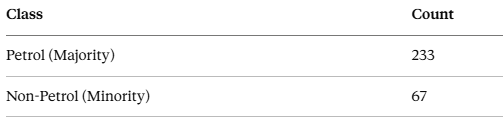

To balance, we randomly select and keep only 67 of the 233 Petrol rows, discarding the other 166. The Non-Petrol rows are left completely untouched.

**After undersampling:**

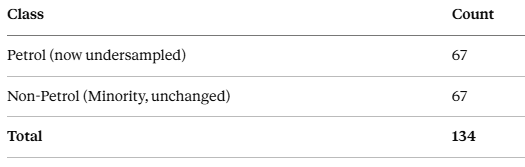

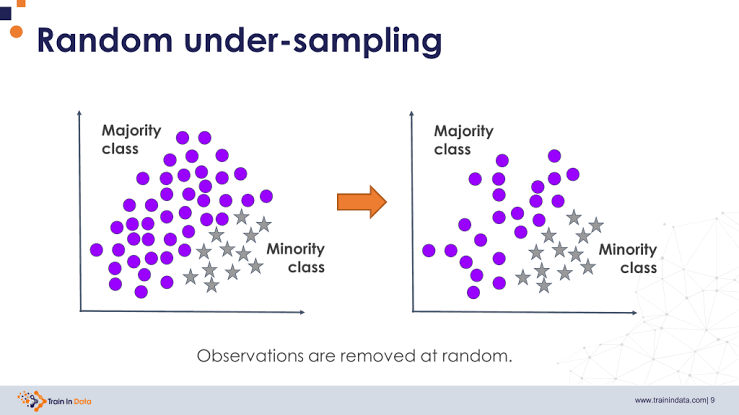

In [ ]:
import pandas as pd
from sklearn.utils import resample

df = pd.read_csv("used_cars_dataset.csv")
df["Class"] = df["Fuel_Type"].apply(lambda x: "Petrol" if x == "Petrol" else "Non-Petrol")

majority = df[df["Class"] == "Petrol"]
minority = df[df["Class"] == "Non-Petrol"]

majority_undersampled = resample(
    majority,
    replace=False,           # no duplicates - we're removing, not repeating
    n_samples=len(minority), # match minority class count (67)
    random_state=42
)

balanced_df = pd.concat([majority_undersampled, minority])
print(balanced_df["Class"].value_counts())
# Petrol        67
# Non-Petrol    67

# Disadvantages

Information loss. We discarded 166 real Petrol car listings — potentially valuable, legitimate data that could have helped the model learn the full variety of what a Petrol car looks like (different brands, price ranges, cities, etc.).

Risk of underfitting. With so little data overall (134 rows), the model has fewer examples to learn general patterns from, and may perform worse simply because it hasn't seen enough variety.

# When to Use Random Undersampling

1. When your dataset is very large and the majority class contains a lot of redundant, similar examples (e.g., millions of near-identical Petrol car listings) — you can afford to trim it down.

2. When training time or computing resources are a major constraint.